<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS11/datasetPBL/Praktikum1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# import library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.preprocessing import StandardScaler

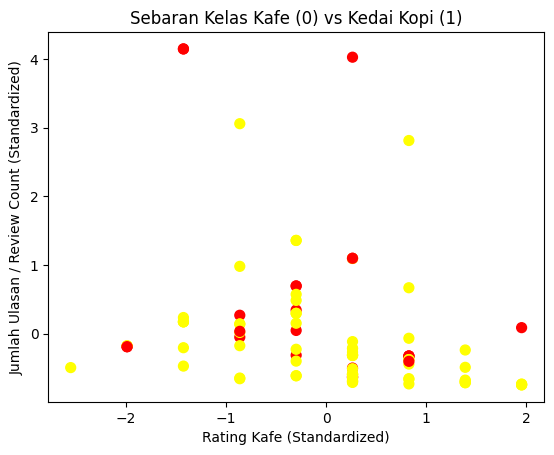

In [2]:
# Load dan gabungkan kedua dataset asli
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')
df = pd.merge(df_reviews, df_cafes, on='cafe_id', how='left', suffixes=('_review', '_cafe'))

# Ambil data kafe unik untuk 2 kelas utama: 'Kafe' (0) vs 'Kedai Kopi' (1)
df_bin = df_cafes[df_cafes['categories'].isin(["['Kafe']", "['Kedai Kopi']"])].copy()

X = StandardScaler().fit_transform(df_bin[['rating', 'review_count']].values)
y = (df_bin['categories'] == "['Kedai Kopi']").astype(int).values

# Plot sebaran 2 kelas data
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.xlabel('Rating Kafe (Standardized)')
plt.ylabel('Jumlah Ulasan / Review Count (Standardized)')
plt.title('Sebaran Kelas Kafe (0) vs Kedai Kopi (1)')
plt.show()

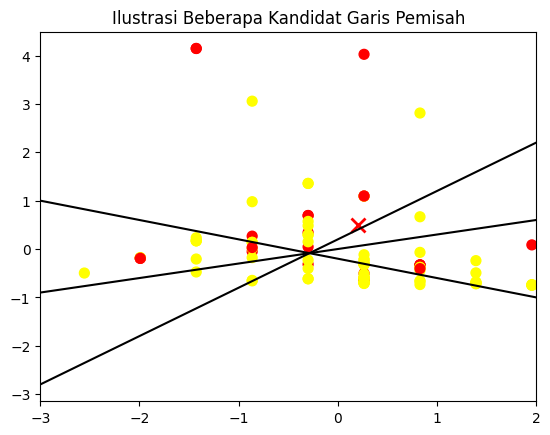

In [3]:
xfit = np.linspace(-3, 2)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.plot([0.2], [0.5], 'x', color='red', markeredgewidth=2, markersize=10)

for m, b in [(1.0, 0.2), (0.3, 0.0), (-0.4, -0.2)]:
    plt.plot(xfit, m * xfit + b, '-k')

plt.xlim(-3, 2)
plt.title('Ilustrasi Beberapa Kandidat Garis Pemisah')
plt.show()

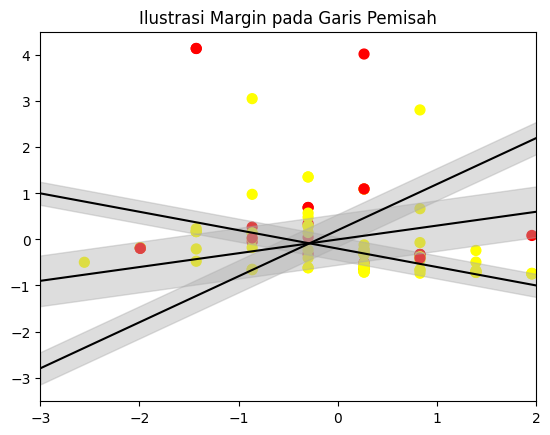

In [4]:
xfit = np.linspace(-3, 2)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

for m, b, d in [(1.0, 0.2, 0.35), (0.3, 0.0, 0.55), (-0.4, -0.2, 0.25)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
                     color='#AAAAAA', alpha=0.4)

plt.xlim(-3, 2)
plt.title('Ilustrasi Margin pada Garis Pemisah')
plt.show()

In [5]:
from sklearn.svm import SVC  # "Support vector classifier"
model = SVC(kernel='linear', C=1.0)
model.fit(X, y)

SVC(kernel='linear')

In [6]:
# buat sebuah fungsi untuk menampilkan fitting data
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X_grid = np.meshgrid(y, x)
    xy = np.vstack([X_grid.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X_grid.shape)

    # plot batas dan margin
    ax.contour(X_grid, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none', edgecolors='k')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

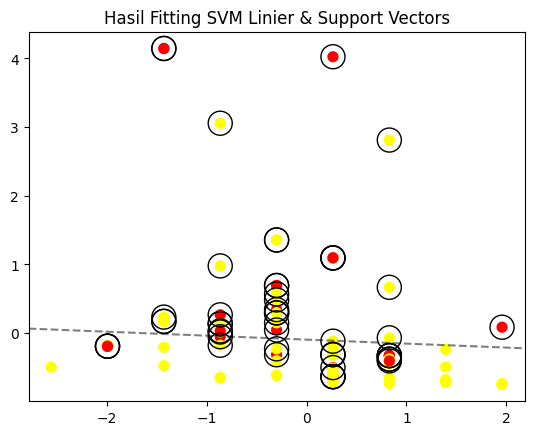

array([[ 0.26432659, -0.63483987],
       [-0.29957013,  0.69269749],
       [-1.99126027, -0.19124216],
       [ 0.8282233 , -0.32798421],
       [ 0.26432659, -0.50298147],
       [-0.29957013,  0.04480066],
       [-0.86346684, -0.05287223],
       [ 0.26432659, -0.63483987],
       [-1.99126027, -0.19124216],
       [ 0.8282233 , -0.32798421],
       [-1.42736356,  4.14543413],
       [-0.29957013,  0.34188903],
       [ 1.95601673,  0.08549769],
       [-0.29957013, -0.31577509],
       [-0.86346684,  0.26619254],
       [ 0.26432659,  4.0249709 ],
       [-0.29957013,  0.69269749],
       [ 0.26432659,  1.09478422],
       [ 0.26432659, -0.63483987],
       [-1.99126027, -0.19124216],
       [ 0.8282233 , -0.32798421],
       [-1.42736356,  4.14543413],
       [ 0.26432659,  1.0964121 ],
       [ 0.8282233 , -0.40530858],
       [-0.86346684,  0.0317776 ],
       [-1.42736356,  0.17014753],
       [ 0.8282233 ,  0.66665138],
       [-0.86346684,  3.05638141],
       [-0.86346684,

In [7]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model)
plt.title('Hasil Fitting SVM Linier & Support Vectors')
plt.show()

# Melihat koordinat titik-titik support vector
model.support_vectors_

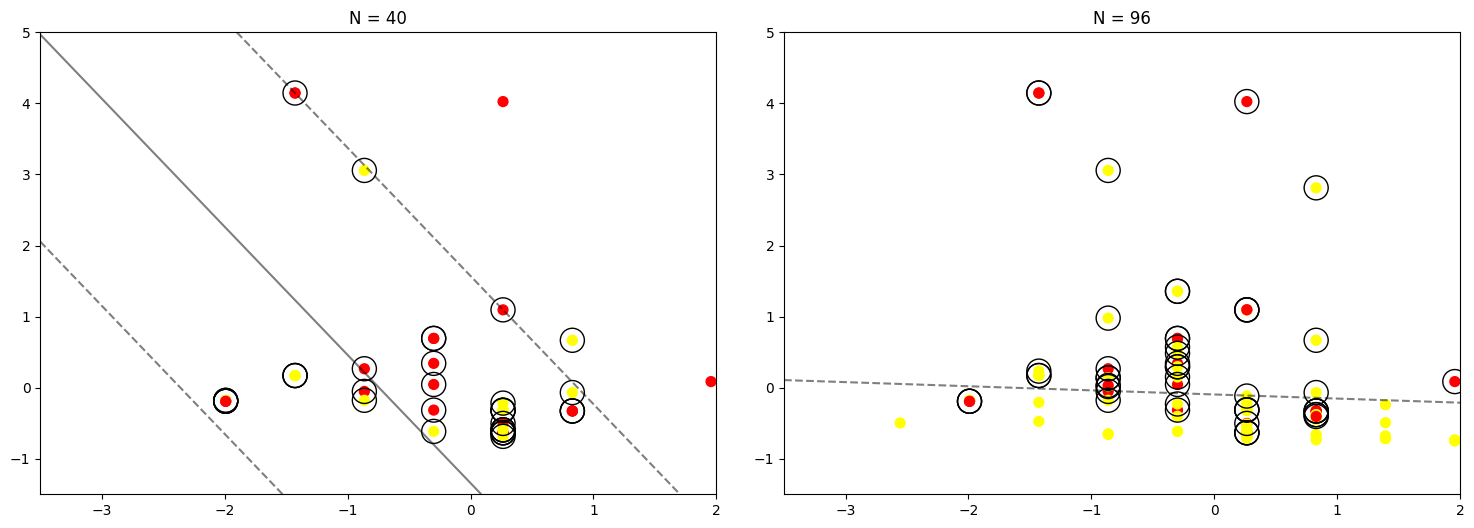

In [8]:
def plot_svm(N=40, ax=None):
    X_sub = X[:N]
    y_sub = y[:N]
    model_sub = SVC(kernel='linear', C=1.0)
    model_sub.fit(X_sub, y_sub)

    ax = ax or plt.gca()
    ax.scatter(X_sub[:, 0], X_sub[:, 1], c=y_sub, s=50, cmap='autumn')
    ax.set_xlim(-3.5, 2.0)
    ax.set_ylim(-1.5, 5.0)
    plot_svc_decision_function(model_sub, ax)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [40, 96]):
    plot_svm(N, axi)
    axi.set_title('N = {0}'.format(N))
plt.show()

In [9]:
# Widget interaktif (opsional, jalankan !pip install ipywidgets terlebih dahulu)
from ipywidgets import interact, fixed
interact(plot_svm, N=[20, 96], ax=fixed(None))

interactive(children=(Dropdown(description='N', options=(20, 96), value=20), Output()), _dom_classes=('widget-…

<function __main__.plot_svm(N=40, ax=None)>